# 13. Self-collected Healthy field and leaf-crop evaluation

This experiment examines Healthy recognition by the four frozen CNN and ViT checkpoints from Notebook 11. The original evaluation covers 57 self-collected Healthy images in Tomato Field Evaluation v2. Its saved predictions are preserved and reused here.

The research questions are: **(1)** Does mixed-domain adaptation change Healthy recognition? **(2)** How does recognition differ across original photographs and accepted leaf crops? **(3)** Within verified source photographs, do crops improve recognition relative to their own originals?

A separate **Exploratory Paired Original–Crop Evaluation** extends original-image coverage to the source photographs of all 49 accepted crops. It does not change the original 57-image evaluation or dataset v2. The labels are human annotations, not laboratory-confirmed diagnoses; this is not an independent five-class field benchmark.

## Healthy Field Dataset

The complete v2 manifest contains 103 images. The original evaluation is restricted to 8 self-collected Healthy originals, 7 retained historical Healthy crops and 42 newly approved Healthy crops (57 images). The 46 online disease images are excluded from model inference in this notebook.

The 42 new crops have explicit human `accept` decisions and no unresolved recorded holds. Historical `keep` approvals were retained under the documented dataset policy. Four accepted proposals with technical holds and historical crop SC_0013 remain excluded. The original annotation workbook supplies the Healthy ground truth.

In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
from uuid import uuid4
from contextlib import redirect_stdout
from html import escape
from urllib.parse import quote
import shutil
import gc, hashlib, importlib.metadata, json, os, platform, subprocess, sys, warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
with warnings.catch_warnings(record=True) as import_warnings:
    warnings.simplefilter("always")
    import torch
    import torchvision
    import timm
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet18_Weights, resnet18
from IPython.display import display, Markdown, HTML

In [2]:
root_override = os.environ.get("PLANT_PROJECT_ROOT")
candidates = [Path(root_override)] if root_override else [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p.resolve() for p in candidates if (p / "notebooks/11_external_evaluation.ipynb").is_file()
                    and (p / "data/splits/label_map.json").is_file())
DATA_ROOT = PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v2"
SPLITS_DIR = PROJECT_ROOT / "data/splits"
BASE_EVALUATION_RUN = PROJECT_ROOT / "outputs/healthy_field_evaluation/tomato_field_eval_v2/20261126_103724_5c4da7f2"
BASE_PROTOCOL = json.loads((BASE_EVALUATION_RUN / "evaluation_protocol.json").read_text())
assert BASE_PROTOCOL["complete_four_model_evaluation"] is True
assert BASE_PROTOCOL["prediction_csv_sha256"] == hashlib.sha256((BASE_EVALUATION_RUN / "image_level_predictions.csv").read_bytes()).hexdigest()
REFERENCE_RUN = PROJECT_ROOT / "outputs/external_evaluation/tomato_field_eval_v1/20261125_163347_4ca8183f"
RUN_ID = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
OUTPUT_ROOT = PROJECT_ROOT / "outputs/healthy_field_evaluation/tomato_field_eval_v2" / ("paired_" + RUN_ID)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
(OUTPUT_ROOT / "audit").mkdir()
(OUTPUT_ROOT / "figures").mkdir()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Read-only integrity record: previous datasets, notebooks, checkpoints and historical results.
protected_dirs = [PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v1", DATA_ROOT,
                  PROJECT_ROOT / "models", PROJECT_ROOT / "outputs/external_evaluation",
                  PROJECT_ROOT / "outputs/external_error_analysis", BASE_EVALUATION_RUN]
PROTECTED = {p: sha256_file(p) for folder in protected_dirs if folder.exists()
             for p in folder.rglob("*") if p.is_file() and p.name != ".DS_Store"}
PROTECTED.update({p: sha256_file(p) for p in (PROJECT_ROOT / "notebooks").glob("*.ipynb")
                  if int(p.name[:2]) <= 12})
VERSIONS = {name: importlib.metadata.version(name) for name in
            ("torch", "torchvision", "timm", "numpy", "pandas", "Pillow", "matplotlib")}
(OUTPUT_ROOT / "audit/environment.log").write_text(json.dumps(VERSIONS, indent=2) + "\n" +
    "\n".join(str(w.message) for w in import_warnings))
DATASET_README_SHA256 = sha256_file(DATA_ROOT / "README.md")
dataset_description = (DATA_ROOT / "README.md").read_text()
validation = subprocess.run([sys.executable, "-B", str(DATA_ROOT / "validate_dataset.py"), str(DATA_ROOT)],
                            capture_output=True, text=True, check=True)
DATASET_VALIDATION = json.loads(validation.stdout)
(OUTPUT_ROOT / "audit/dataset_validation.json").write_text(json.dumps(DATASET_VALIDATION, indent=2))
assert DATASET_VALIDATION["status"] == "passed"

In [3]:
CANONICAL_MAP = {"Healthy": 0, "Early Blight": 1, "Late Blight": 2,
                 "Bacterial Spot": 3, "Septoria Leaf Spot": 4}
LABEL_MAP = json.loads((SPLITS_DIR / "label_map.json").read_text())
assert LABEL_MAP == CANONICAL_MAP == json.loads((DATA_ROOT / "class_mapping.json").read_text())
CLASS_NAMES, LABEL_IDS = list(CANONICAL_MAP), list(range(5))
manifest = pd.read_csv(DATA_ROOT / "manifest.csv", keep_default_na=False)
required = {"image_id", "image_path", "original_filename", "parent_image_id", "plant_id", "scene_group_id",
            "leaf_group_id", "evaluation_subset", "is_crop", "crop_coordinates", "sha256", "parent_sha256",
            "approval_basis", "human_review_decision", "review_status", "annotation_source", "label_source",
            "technical_hold", "duplicate_hold", "annotation_hold", "source", "class_name", "label_id"}
assert required <= set(manifest.columns)
assert len(manifest) == 103 and manifest.image_id.is_unique and manifest.sha256.is_unique
healthy = manifest.loc[manifest.source.eq("self_collected") & manifest.class_name.eq("Healthy")].copy()
assert len(healthy) == 57 and healthy.label_id.eq(0).all()
healthy["is_crop"] = healthy.is_crop.astype(str).str.lower().map({"true": True, "false": False})
assert healthy.is_crop.notna().all()
healthy["analysis_subset"] = np.select(
    [~healthy.is_crop, healthy.approval_basis.eq("historical_v1_keep"),
     healthy.approval_basis.eq("explicit_human_accept")],
    ["Original photographs", "Historical crops", "Newly approved crops"], default="unexpected")
SUBSETS = {"Original photographs": 8, "Historical crops": 7, "Newly approved crops": 42, "All crops": 49}
assert healthy.analysis_subset.value_counts().to_dict() == {k: v for k, v in SUBSETS.items() if k != "All crops"}
assert healthy.loc[healthy.is_crop, "evaluation_subset"].eq("healthy_leaf_crops").all()
assert healthy.loc[~healthy.is_crop, "evaluation_subset"].eq("healthy_field_originals").all()
assert healthy.label_source.eq("human_annotated_healthy").all()
assert healthy[["parent_image_id", "plant_id", "scene_group_id"]].ne("").all().all()
for column in ("technical_hold", "duplicate_hold", "annotation_hold"):
    assert healthy[column].astype(str).str.lower().eq("false").all()
assert healthy.loc[healthy.analysis_subset.eq("Newly approved crops"), "human_review_decision"].eq("accept").all()
assert not healthy.image_id.isin(["HLV3_0018", "HLV3_0043", "HLV3_0084", "HLV3_0146", "SC_0013"]).any()
assert not healthy.plant_id.isin(["P020", "P031", "P032"]).any()
healthy = healthy.reset_index(drop=True)
image_paths = [DATA_ROOT / p for p in healthy.image_path]
assert all(sha256_file(p) == h for p, h in zip(image_paths, healthy.sha256))
MANIFEST_SHA256 = sha256_file(DATA_ROOT / "manifest.csv")
healthy.to_csv(OUTPUT_ROOT / "evaluated_manifest.csv", index=False)
composition = healthy.groupby("analysis_subset", sort=False).agg(
    images=("image_id", "size"), source_photographs=("parent_image_id", "nunique"),
    recorded_scene_groups=("scene_group_id", "nunique"))
composition.to_csv(OUTPUT_ROOT / "dataset_composition.csv")
display(composition.rename(columns=lambda c: c.replace("_", " ").title()))

,Images,Source Photographs,Recorded Scene Groups
analysis_subset,,,
Original photographs,8,8,8
Historical crops,7,7,7
Newly approved crops,42,20,19


## Models and Evaluation Methodology

### Frozen models and preprocessing

The architectures, strict state loading and evaluation transforms below are reused from Notebook 11. Checkpoint and source-checkpoint hashes must match its completed reference run; adapted checkpoint metadata must match the original Field Dev and Lab Validation manifests. No weights, thresholds or checkpoints are selected using v2.

ResNet18 uses torchvision ImageNet bilinear resize to 256 and center crop to 224. ViT-Small uses its laboratory source checkpoint's stored timm configuration: bicubic resize, center crop to 224 and the recorded normalization. Inference uses float32, five-class argmax, no test-time augmentation and no gradient updates. Confidence is the maximum **uncalibrated softmax score**.

The original 57-image predictions are loaded from their validated saved run. Only the 22 previously unevaluated source photographs receive new inference in the exploratory extension.

In [4]:
# Paths are taken from notebooks 02–03 and 09–10, not inferred from arbitrary file names.
DRIVE_ROOT = Path(os.environ.get(
    "PLANT_DRIVE_ROOT", "/content/drive/MyDrive/plant-disease-diagnosis"
))
USE_DRIVE = DRIVE_ROOT.is_dir()
MODEL_SPECS = {
    "resnet_lab": {
        "model": "ResNet18 · Lab baseline", "architecture": "resnet18", "phase": "lab_only",
        "checkpoint": DRIVE_ROOT / "resnet18_baseline/resnet18_lab_best.pt" if USE_DRIVE
                      else PROJECT_ROOT / "models/resnet18_lab_best.pt",
        "batch_size": 32,
    },
    "vit_lab": {
        "model": "ViT-Small · Lab baseline", "architecture": "vit_small_patch16_224.augreg_in1k",
        "phase": "lab_only",
        "checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt" if USE_DRIVE
                      else PROJECT_ROOT / "models/vit_small_lab_best.pt",
        "batch_size": 16,
    },
    "resnet_mixed": {
        "model": "ResNet18 · Geometric + Mixed", "architecture": "resnet18", "phase": "mixed_domain",
        "experiment": "R2_resnet_geometric",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/R2_resnet_geometric/mixed_domain_best.pt"
                      if USE_DRIVE else PROJECT_ROOT / "models/resnet18_geometric_mixed_best.pt",
        "batch_size": 32,
    },
    "vit_mixed": {
        "model": "ViT-Small · Mixed", "architecture": "vit_small_patch16_224.augreg_in1k",
        "phase": "mixed_domain", "experiment": "V1_vit_small",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/V1_vit_small/mixed_domain_best.pt"
                      if USE_DRIVE else PROJECT_ROOT / "models/vit_small_mixed_best.pt",
        "batch_size": 16,
    },
}
MODEL_SPECS["resnet_lab"]["source_checkpoint"] = MODEL_SPECS["resnet_lab"]["checkpoint"]
MODEL_SPECS["vit_lab"]["source_checkpoint"] = MODEL_SPECS["vit_lab"]["checkpoint"]
MODEL_SPECS["resnet_mixed"]["source_checkpoint"] = (
    DRIVE_ROOT / "resnet18_aug_geometric/resnet18_best.pt" if USE_DRIVE
    else PROJECT_ROOT / "models/resnet18_aug_geometric_best.pt"
)
MODEL_SPECS["vit_mixed"]["source_checkpoint"] = MODEL_SPECS["vit_lab"]["checkpoint"]

In [5]:
reference_protocol = json.loads((REFERENCE_RUN / "evaluation_protocol.json").read_text())
assert reference_protocol["complete_four_model_evaluation"] is True
assert reference_protocol["class_mapping"] == LABEL_MAP
assert reference_protocol["manifest_sha256"] == sha256_file(
    PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v1/manifest.csv")
assert reference_protocol["summary_sha256"] == sha256_file(REFERENCE_RUN / "model_summary.csv")
SPLIT_HASHES = {name: sha256_file(SPLITS_DIR / f"{name}.csv") for name in ("field_dev", "lab_val", "lab_test")}
for key, spec in MODEL_SPECS.items():
    recorded = reference_protocol["checkpoints_and_preprocessing"][key]
    for field in ("checkpoint", "source_checkpoint"):
        assert spec[field].is_file()
        assert sha256_file(spec[field]) == recorded[f"{field}_sha256"], (key, field)
    assert recorded["architecture"] == spec["architecture"]
    assert reference_protocol["prediction_files_sha256"][key] == sha256_file(REFERENCE_RUN / f"predictions_{key}.csv")
SHORT_NAMES = {"resnet_lab": "ResNet18 lab", "vit_lab": "ViT-Small lab",
               "resnet_mixed": "ResNet18 mixed", "vit_mixed": "ViT-Small mixed"}
MODEL_COLORS = {"resnet_lab": "#527a9f", "vit_lab": "#bd7f2f",
                "resnet_mixed": "#164d73", "vit_mixed": "#805016"}

In [6]:
def load_fixed_model(key):
    spec = MODEL_SPECS[key]
    state = torch.load(spec["checkpoint"], map_location="cpu", weights_only=True)
    source = torch.load(spec["source_checkpoint"], map_location="cpu", weights_only=True)
    for record in (state, source):
        assert list(record["class_names"]) == CLASS_NAMES, f"Label order mismatch: {key}"
        assert record["architecture"] == spec["architecture"], f"Architecture mismatch: {key}"
    if spec["phase"] == "mixed_domain":
        assert state["adaptation_type"] == "balanced_mixed_domain"
        assert state["experiment"] == spec["experiment"]
        assert state["field_dev_sha256"] == SPLIT_HASHES["field_dev"]
        assert state["manifest_sha256"]["lab_val"] == SPLIT_HASHES["lab_val"]
        assert state["source_checkpoint_sha256"] == sha256_file(spec["source_checkpoint"])
    if spec["architecture"] == "resnet18":
        assert source["pretrained_weights"] == "IMAGENET1K_V1"
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 5)
        transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
        config = {"source": "torchvision.ResNet18_Weights.IMAGENET1K_V1.transforms"}
    else:
        assert source["pretrained_weights"] == "augreg_in1k"
        config = source["preprocessing_config"]
        assert tuple(config["input_size"]) == (3, 224, 224)
        model = timm.create_model(spec["architecture"], pretrained=False, num_classes=5)
        transform = timm.data.create_transform(**config, is_training=False)
    model.load_state_dict(state["model_state_dict"], strict=True)
    model.to(DEVICE).eval()
    model.requires_grad_(False)
    provenance = {
        "checkpoint": str(spec["checkpoint"]), "checkpoint_sha256": sha256_file(spec["checkpoint"]),
        "source_checkpoint": str(spec["source_checkpoint"]),
        "source_checkpoint_sha256": sha256_file(spec["source_checkpoint"]),
        "architecture": spec["architecture"], "phase": spec["phase"],
        "preprocessing_config": config, "transform": repr(transform),
        "checkpoint_metadata": {k: v for k, v in state.items() if k != "model_state_dict"},
    }
    return model, transform, provenance

### Measures and units of analysis

Healthy recall is the number predicted Healthy divided by the number of human-labeled Healthy images. The false disease alarm rate is its complement. Report correct counts and all four predicted disease destinations; five-class Macro-F1 is not a primary measure for this one-class population.

For crop-level summaries, first calculate recall within each parent photograph and then average those recalls with equal parent weights. Scene summaries similarly average parent recalls within each recorded scene, then weight scenes equally. Groups are provenance identifiers, not verified independent physical plants.

Direct original–crop comparisons require the same parent identifier **and parent image hash**. Crops whose source is absent from the eight evaluation originals remain unpaired. All comparisons are exploratory; cropping is not an isolated causal intervention.

In [7]:
# Reuse the original predictions without re-inference or reserializing their CSV values.
assert BASE_PROTOCOL["manifest_sha256"] == MANIFEST_SHA256
prediction_frames = {}
for key, spec in MODEL_SPECS.items():
    source = BASE_EVALUATION_RUN / f"predictions_{key}.csv"
    frame = pd.read_csv(source, keep_default_na=False)
    assert len(frame) == 57 and frame.image_id.tolist() == healthy.image_id.tolist()
    assert frame.sha256.tolist() == healthy.sha256.tolist()
    assert frame.class_name.eq("Healthy").all() and frame.source.eq("self_collected").all()
    assert frame.correct.eq(frame.predicted_label_id.eq(0)).all()
    assert sha256_file(spec["checkpoint"]) == BASE_PROTOCOL["checkpoints_and_preprocessing"][key]["checkpoint_sha256"]
    prediction_frames[key] = frame
    shutil.copy2(source, OUTPUT_ROOT / source.name)
provenance_records = BASE_PROTOCOL["checkpoints_and_preprocessing"]
predictions = pd.concat(prediction_frames.values(), ignore_index=True)
assert len(predictions) == 228
shutil.copy2(BASE_EVALUATION_RUN / "image_level_predictions.csv", OUTPUT_ROOT / "image_level_predictions.csv")

PosixPath('/Volumes/Lexar E6/Code/plant-disease-diagnosis/outputs/healthy_field_evaluation/tomato_field_eval_v2/paired_20261126_105328_eddcf985/image_level_predictions.csv')

In [8]:
def healthy_metrics(frame):
    correct, count = int(frame.correct.sum()), len(frame)
    row = {"images": count, "correct": correct, "healthy_recall": correct / count,
           "false_disease_alarm_rate": (count - correct) / count}
    for label, name in enumerate(CLASS_NAMES):
        row[f"predicted_{name.lower().replace(' ', '_')}"] = int(frame.predicted_label_id.eq(label).sum())
    return row

metric_rows = []
for key, frame in prediction_frames.items():
    for name in SUBSETS:
        group = frame.loc[frame.is_crop] if name == "All crops" else frame.loc[frame.analysis_subset.eq(name)]
        assert len(group) == SUBSETS[name]
        metric_rows.append({"model_key": key, "model": MODEL_SPECS[key]["model"], "subset": name,
                            **healthy_metrics(group)})
subset_metrics = pd.DataFrame(metric_rows)
subset_metrics.to_csv(OUTPUT_ROOT / "subset_metrics.csv", index=False)
model_summary = pd.DataFrame([{"model_key": key, "model": MODEL_SPECS[key]["model"],
                               "status": "evaluated", **healthy_metrics(frame)}
                              for key, frame in prediction_frames.items()])
model_summary.to_csv(OUTPUT_ROOT / "model_summary.csv", index=False)

## Healthy Recognition Results

### Healthy recognition by image subset

The four subsets retain their own denominators. “All crops” combines the historical and newly approved crop subsets and is not an additional independent sample. Healthy recall and false disease alarm rate sum to one because every ground-truth label is Healthy.

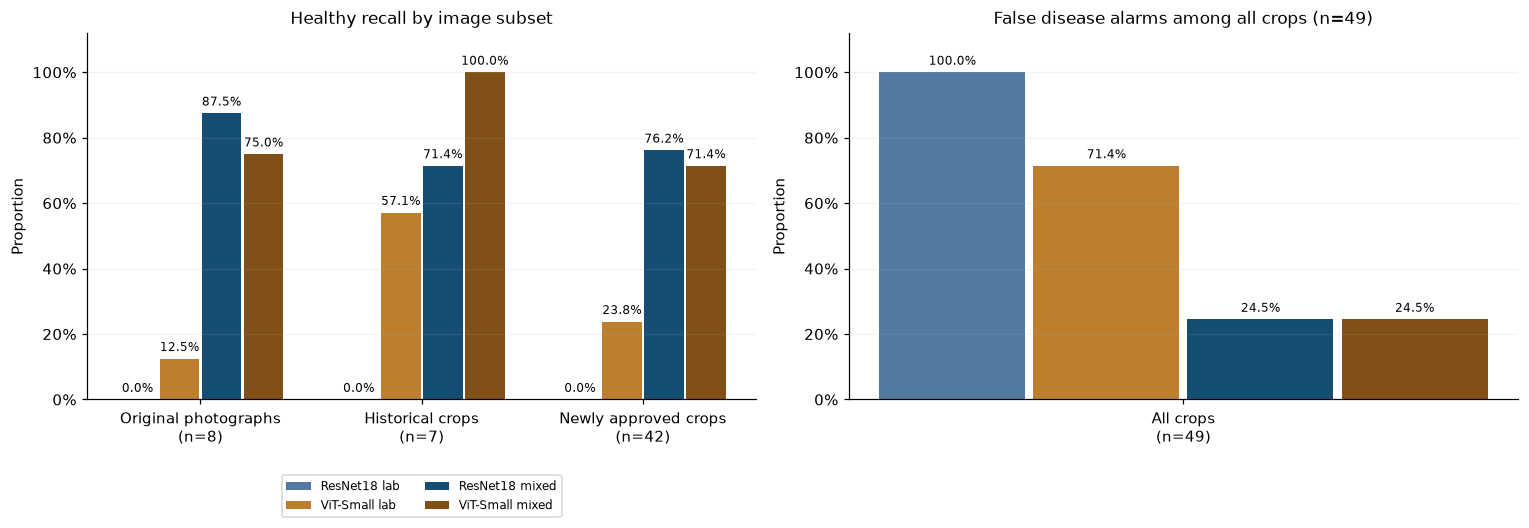

In [9]:
result_table = subset_metrics.assign(
    correct_over_images=subset_metrics.correct.astype(str) + "/" + subset_metrics.images.astype(str))
readout = result_table.assign(model_name=result_table.model_key.map(SHORT_NAMES))
readout["subset"] = pd.Categorical(readout.subset, categories=list(SUBSETS), ordered=True)
readout["model_name"] = pd.Categorical(readout.model_name, categories=list(SHORT_NAMES.values()), ordered=True)
readout = readout.sort_values(["subset", "model_name"]).set_index(["subset", "model_name"])
display(readout[["correct_over_images", "healthy_recall", "false_disease_alarm_rate"]]
        .rename(columns={"correct_over_images": "Correct / images", "healthy_recall": "Healthy recall",
                         "false_disease_alarm_rate": "False disease alarm rate"})
        .style.format({"Healthy recall": "{:.1%}", "False disease alarm rate": "{:.1%}"}))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, names, title in [(axes[0], ["Original photographs", "Historical crops", "Newly approved crops"],
                         "Healthy recall by image subset"),
                        (axes[1], ["All crops"], "False disease alarms among all crops (n=49)")]:
    for i, key in enumerate(MODEL_SPECS):
        rows = subset_metrics.loc[subset_metrics.model_key.eq(key)].set_index("subset").loc[names]
        metric = "healthy_recall" if ax is axes[0] else "false_disease_alarm_rate"
        x = np.arange(len(names)) + (i - 1.5) * .19
        bars = ax.bar(x, rows[metric], width=.18, color=MODEL_COLORS[key], label=SHORT_NAMES[key])
        ax.bar_label(bars, labels=[f"{v:.1%}" for v in rows[metric]], padding=3, fontsize=8)
    labels = [f"{name}\n(n={SUBSETS[name]})" for name in names]
    ax.set(xticks=np.arange(len(names)), xticklabels=labels, ylim=(0, 1.12), ylabel="Proportion", title=title)
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis="y", alpha=.15)
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "figures/subset_healthy_recognition.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

In [10]:
summary_scores = model_summary.set_index("model_key")
notes = []
for arch, title in (("resnet", "ResNet18"), ("vit", "ViT-Small")):
    b, m = summary_scores.loc[f"{arch}_lab"], summary_scores.loc[f"{arch}_mixed"]
    notes.append(f"**{title}:** {int(b.correct)}/57 → {int(m.correct)}/57 correct "
                 f"({b.healthy_recall:.1%} → {m.healthy_recall:.1%}); "
                 f"a {100*(m.healthy_recall-b.healthy_recall):+.1f} percentage-point difference.")
display(Markdown("\n\n".join(notes)))

**ResNet18:** 0/57 → 44/57 correct (0.0% → 77.2%); a +77.2 percentage-point difference.

**ViT-Small:** 15/57 → 43/57 correct (26.3% → 75.4%); a +49.1 percentage-point difference.

### False disease destinations

Every non-Healthy prediction is a false disease alarm against the preserved human ground truth. Destination counts describe model confusion; they do not provide evidence that a source photograph should be relabeled.

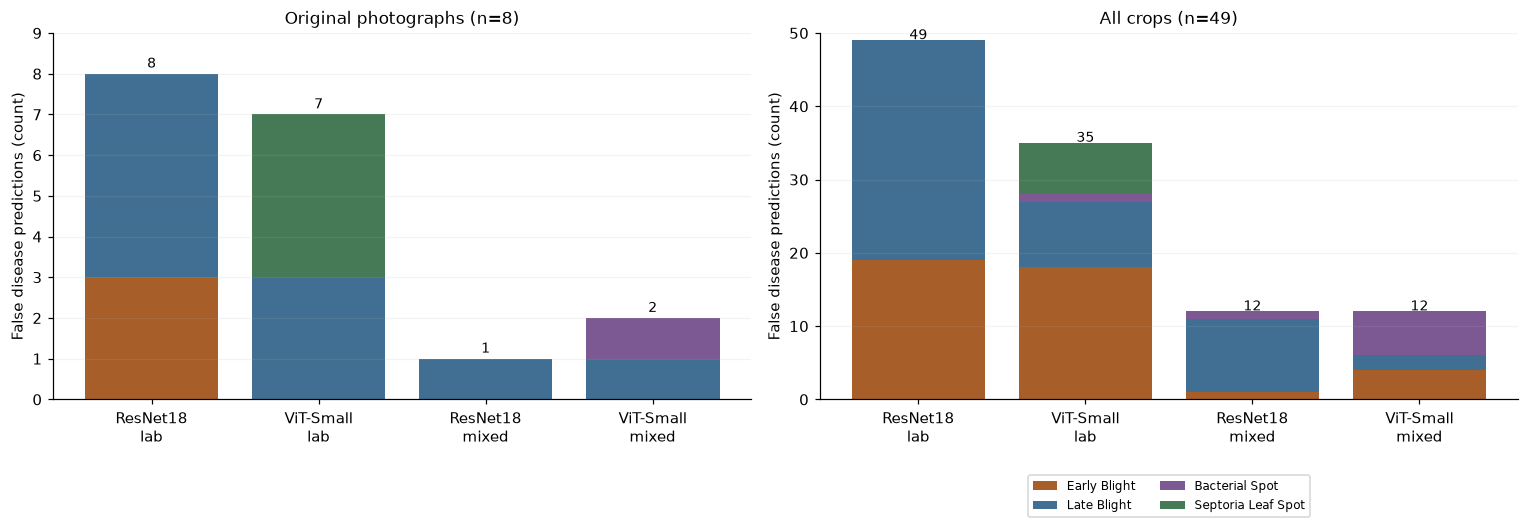

In [11]:
disease_rows = []
for row in subset_metrics.itertuples():
    for name in CLASS_NAMES[1:]:
        count = getattr(row, "predicted_" + name.lower().replace(" ", "_"))
        disease_rows.append({"model_key": row.model_key, "subset": row.subset,
                             "predicted_disease": name, "count": count, "images": row.images})
disease_distribution = pd.DataFrame(disease_rows)
disease_distribution.to_csv(OUTPUT_ROOT / "predicted_disease_distribution.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
disease_colors = ["#a75e28", "#406f93", "#7c5993", "#467a56"]
for ax, subset in zip(axes, ("Original photographs", "All crops")):
    bottom = np.zeros(4)
    for name, color in zip(CLASS_NAMES[1:], disease_colors):
        values = disease_distribution.loc[disease_distribution.subset.eq(subset) &
            disease_distribution.predicted_disease.eq(name)].set_index("model_key")["count"].reindex(MODEL_SPECS)
        ax.bar(np.arange(4), values, bottom=bottom, color=color, label=name)
        bottom += values.to_numpy()
    for i, count in enumerate(bottom):ax.text(i, count + .15, str(int(count)), ha="center", fontsize=9)
    ax.set(xticks=np.arange(4), xticklabels=[s.replace(" ", "\n", 1) for s in SHORT_NAMES.values()],
           ylabel="False disease predictions (count)", title=f"{subset} (n={SUBSETS[subset]})", ylim=(0, SUBSETS[subset]+1))
    ax.grid(axis="y", alpha=.15)
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2)
fig.tight_layout();fig.savefig(OUTPUT_ROOT / "figures/false_disease_destinations.png", dpi=160, bbox_inches="tight")
plt.show();plt.close(fig)

### Parent- and scene-weighted crop summaries

A source photograph with many accepted crops contributes one parent mean rather than one vote per crop. Within a recorded scene, parent means are averaged before taking the equal-scene mean. These summaries reduce unequal crop-count weighting but do not establish independence or make the selected scenes representative.

,subset,crops,parents,scenes,image_weighted_recall,equal_parent_recall,equal_scene_parent_balanced_recall
model_key,,,,,,,
ResNet18 lab,All crops,49,23,21,0.000,0.000,0.000
ViT-Small lab,All crops,49,23,21,0.286,0.353,0.363
ResNet18 mixed,All crops,49,23,21,0.755,0.756,0.780
ViT-Small mixed,All crops,49,23,21,0.755,0.828,0.811


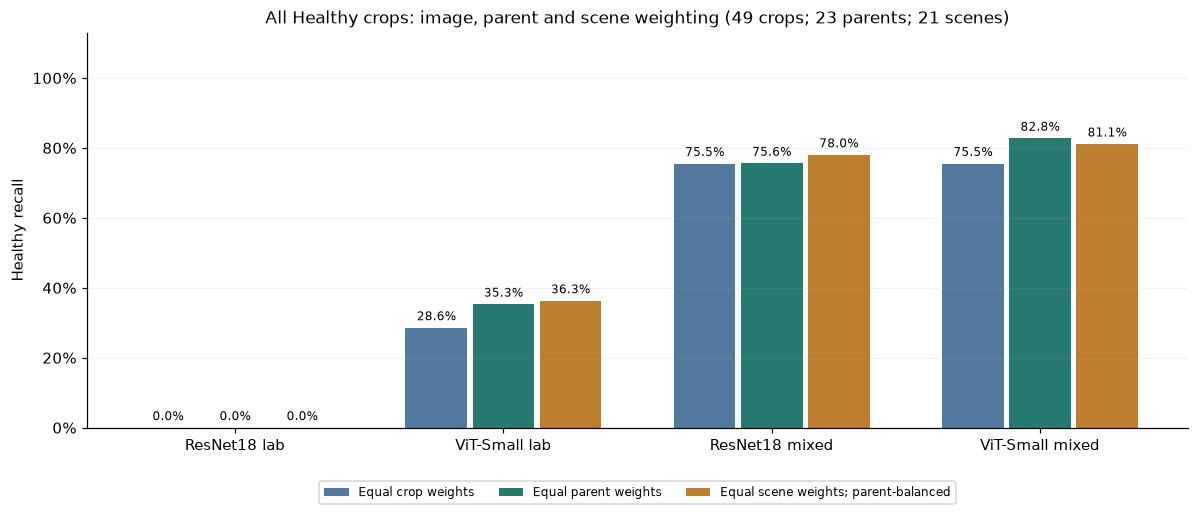

In [12]:
parent_rows = []
for key, frame in prediction_frames.items():
    for subset in ("Historical crops", "Newly approved crops", "All crops"):
        selected = frame.loc[frame.is_crop] if subset == "All crops" else frame.loc[frame.analysis_subset.eq(subset)]
        for (parent, scene, plant), group in selected.groupby(["parent_image_id", "scene_group_id", "plant_id"], sort=True):
            parent_rows.append({"model_key": key, "subset": subset, "parent_image_id": parent,
                "scene_group_id": scene, "plant_id": plant, "crop_ids": " | ".join(group.image_id),
                **healthy_metrics(group)})
parent_summary = pd.DataFrame(parent_rows)
parent_summary.to_csv(OUTPUT_ROOT / "parent_summary.csv", index=False)
scene_summary = parent_summary.groupby(["model_key", "subset", "scene_group_id"], as_index=False).agg(
    source_photographs=("parent_image_id", "nunique"), crops=("images", "sum"),
    parent_balanced_healthy_recall=("healthy_recall", "mean"))
scene_summary["false_disease_alarm_rate"] = 1 - scene_summary.parent_balanced_healthy_recall
scene_summary.to_csv(OUTPUT_ROOT / "scene_summary.csv", index=False)
weighted_rows = []
for (key, subset), group in parent_summary.groupby(["model_key", "subset"], sort=False):
    scenes = scene_summary.loc[scene_summary.model_key.eq(key) & scene_summary.subset.eq(subset)]
    image_score = subset_metrics.loc[subset_metrics.model_key.eq(key) & subset_metrics.subset.eq(subset)].iloc[0]
    weighted_rows.append({"model_key": key, "subset": subset, "crops": int(group.images.sum()),
        "parents": len(group), "scenes": len(scenes), "image_weighted_recall": image_score.healthy_recall,
        "equal_parent_recall": group.healthy_recall.mean(),
        "equal_scene_parent_balanced_recall": scenes.parent_balanced_healthy_recall.mean()})
weighted_summary = pd.DataFrame(weighted_rows)
weighted_summary.to_csv(OUTPUT_ROOT / "weighted_crop_summary.csv", index=False)
display(weighted_summary.loc[weighted_summary.subset.eq("All crops")].set_index("model_key")
        .rename(index=SHORT_NAMES).round(3))
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (metric, label, color) in enumerate([
    ("image_weighted_recall", "Equal crop weights", "#527a9f"),
    ("equal_parent_recall", "Equal parent weights", "#267a70"),
    ("equal_scene_parent_balanced_recall", "Equal scene weights; parent-balanced", "#bd7f2f")]):
    values = weighted_summary.loc[weighted_summary.subset.eq("All crops")].set_index("model_key")[metric].reindex(MODEL_SPECS)
    bars = ax.bar(np.arange(4)+(i-1)*.25, values, width=.23, label=label, color=color)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=3, fontsize=8)
ax.set(xticks=np.arange(4), xticklabels=SHORT_NAMES.values(), ylim=(0, 1.13), ylabel="Healthy recall",
       title="All Healthy crops: image, parent and scene weighting (49 crops; 23 parents; 21 scenes)")
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.grid(axis="y", alpha=.15)
ax.legend(loc="upper center", bbox_to_anchor=(.5,-.12), ncol=3, fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT_ROOT / "figures/crop_weighting_comparison.png", dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)

## Original vs Leaf-Crop Analysis

### Existing 57-image paired evaluation

The relationship audit below distinguishes the manifest's `image_id` (for example SC_0011) from the source-photo `parent_image_id` (IMG_3793) and original filename. Matching uses the original filename and source SHA-256 together, with identifiers checked for consistency.

All 49 crops are traceable to 23 source photographs in 21 recorded scene groups. Only IMG_3793 is one of the eight evaluated originals. Its crop HLV3_0064 is the sole existing direct pair; the other 48 crops come from 22 locally available parents without original-image predictions in the 57-image evaluation. This is incomplete evaluation coverage, not a mapping error.

The other raw parents are stored as provenance inputs for crop-coordinate checks, not as manifest-listed evaluation originals. Their availability on disk did not supply original-image predictions.

In [13]:
# Identify originals by filename AND source bytes; image_id and parent_image_id need not share a format.
import runpy
validation_tools = runpy.run_path(str(DATA_ROOT / "validate_dataset.py"), run_name="_parent_audit_tools")
read_workbook = validation_tools["read_workbook"]
RAW_ROOT = Path(os.environ.get("PLANT_RAW_ROOT", "/Users/thutrang/Downloads/tomato_field_raw"))
ANNOTATION_PATH = RAW_ROOT / "Tomato Field Photo Review.xlsx"
annotation_sheets = read_workbook(ANNOTATION_PATH)
annotation_records = [r for r in annotation_sheets["review"] if r.get("filename")]
assert len({r["filename"].casefold() for r in annotation_records}) == len(annotation_records)
annotations = {r["filename"].casefold(): r for r in annotation_records}
assert sha256_file(ANNOTATION_PATH) == sha256_file(DATA_ROOT / "provenance/inputs/Tomato Field Photo Review.xlsx")
current_review_path = RAW_ROOT / "healthy_leaf_crops_review_v3/final_review_workbook.xlsx"
assert sha256_file(current_review_path) == sha256_file(DATA_ROOT / "provenance/inputs/final_review_workbook.xlsx")
review_decisions = {r["Crop ID"]: r for r in read_workbook(current_review_path)["New candidates"]}
PROTECTED[ANNOTATION_PATH] = sha256_file(ANNOTATION_PATH)
PROTECTED[current_review_path] = sha256_file(current_review_path)
v1_manifest = pd.read_csv(PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v1/manifest.csv", keep_default_na=False)
v1_by_id = v1_manifest.set_index("image_id")
review_mapping = pd.read_csv(DATA_ROOT / "provenance/inputs/crop_mapping.csv", keep_default_na=False).set_index("crop_id")
original_evaluation = healthy.loc[~healthy.is_crop].copy()
crop_evaluation = healthy.loc[healthy.is_crop].copy()
assert len(crop_evaluation) == 49
mapping_rows = []
for crop in crop_evaluation.itertuples():
    filename = crop.original_filename
    assert crop.parent_filename == filename
    annotation = annotations[filename.casefold()]
    assert annotation["source"].strip().lower() == "self_collected"
    assert annotation["class_name"].strip().lower() == "healthy"
    assert annotation["plant_id"] == crop.plant_id
    assert crop.plant_id not in {"P020", "P031", "P032"}, "Unresolved annotation/duplicate scene"
    source = RAW_ROOT / "self_collected" / filename
    assert source.is_file() and source.name == filename
    source_hash = sha256_file(source)
    assert source_hash == crop.parent_sha256 == sha256_file(DATA_ROOT / crop.parent_image_path)
    PROTECTED[source] = source_hash
    box = json.loads(crop.crop_coordinates)
    with Image.open(source) as im:
        parent = ImageOps.exif_transpose(im).convert("RGB")
        assert 0 <= box[0] < box[2] <= parent.width and 0 <= box[1] < box[3] <= parent.height
        target = parent.crop(box)
    with Image.open(DATA_ROOT / crop.image_path) as im:
        actual = im.convert("RGB")
        assert actual.size == target.size and actual.tobytes() == target.tobytes()
    assert sha256_file(DATA_ROOT / crop.image_path) == crop.crop_sha256 == crop.sha256
    if crop.approval_basis == "explicit_human_accept":
        assert review_decisions[crop.image_id]["Review decision"] == "accept"
        prepared = review_mapping.loc[crop.image_id]
        assert prepared.crop_sha256 == crop.sha256 and prepared.parent_sha256 == source_hash
        assert json.loads(prepared.crop_coordinates) == box
    else:
        assert crop.approval_basis == "historical_v1_keep"
        assert v1_by_id.loc[crop.image_id, "sha256"] == crop.sha256
        assert v1_by_id.loc[crop.image_id, "original_filename"] == filename
    matches = original_evaluation.loc[original_evaluation.original_filename.eq(filename) &
                                       original_evaluation.sha256.eq(source_hash)]
    assert len(matches) <= 1
    filename_matches = original_evaluation.loc[original_evaluation.original_filename.eq(filename)]
    assert filename_matches.empty or len(matches) == 1, "Filename matches but bytes differ"
    present = len(matches) == 1
    if present:
        assert matches.iloc[0].parent_image_id == crop.parent_image_id
    mapping_rows.append({"crop_id": crop.image_id, "crop_filename": crop.filename,
        "parent_filename": filename, "parent_image_id": crop.parent_image_id,
        "parent_sha256": source_hash, "plant_id": crop.plant_id, "scene_group_id": crop.scene_group_id,
        "parent_in_v2_evaluation": present, "pairing_status": "existing_evaluated_parent" if present else "verified_parent_not_evaluated",
        "pairing_explanation": "Original is one of the eight evaluation originals; filename and bytes match." if present else
            "Original exists locally and is human-labeled Healthy, but is absent from the eight evaluated originals; not a mapping error.",
        "evaluated_original_image_id": matches.iloc[0].image_id if present else "",
        "source_path": str(source), "crop_image_path": crop.image_path, "crop_sha256": crop.sha256,
        "crop_coordinates": crop.crop_coordinates, "annotation_excel_row": annotation["_excel_row"],
        "annotation_class_name": annotation["class_name"], "annotation_decision": annotation["decision"],
        "annotation_note": annotation.get("note", ""), "source_available": True,
        "coordinates_verified": True, "provenance_verified": True, "exploratory_eligible": True})
mapping_audit = pd.DataFrame(mapping_rows)
assert len(mapping_audit) == 49 and mapping_audit.crop_id.is_unique
mapping_audit.to_csv(OUTPUT_ROOT / "parent_crop_mapping_audit.csv", index=False)
canonical_audit = PROJECT_ROOT / "outputs/healthy_field_evaluation/parent_crop_mapping_audit.csv"
if canonical_audit.exists():
    assert canonical_audit.read_bytes() == (OUTPUT_ROOT / "parent_crop_mapping_audit.csv").read_bytes(), "Existing audit differs; preserve it for review"
else:
    canonical_audit.write_bytes((OUTPUT_ROOT / "parent_crop_mapping_audit.csv").read_bytes())
parent_sources = mapping_audit.drop_duplicates(["parent_filename", "parent_sha256"]).copy()
assert parent_sources.parent_sha256.is_unique and parent_sources.parent_image_id.is_unique
assert len(parent_sources) == 23 and parent_sources.scene_group_id.nunique() == 21
assert mapping_audit.parent_in_v2_evaluation.sum() == 1
assert parent_sources.parent_in_v2_evaluation.sum() == 1
parent_sources.to_csv(OUTPUT_ROOT / "audit/verified_parent_sources.csv", index=False)
coverage = pd.DataFrame({"Coverage": ["Healthy crops audited", "Verified source photographs", "Recorded scene groups",
    "Parents already evaluated as originals", "Additional source photographs needed", "Mapping errors"],
    "Count": [len(mapping_audit), len(parent_sources), parent_sources.scene_group_id.nunique(),
              int(parent_sources.parent_in_v2_evaluation.sum()), int((~parent_sources.parent_in_v2_evaluation).sum()), 0]})
display(coverage.set_index("Coverage"))


,Count
Coverage,
Healthy crops audited,49
Verified source photographs,23
Recorded scene groups,21
Parents already evaluated as originals,1
Additional source photographs needed,22
Mapping errors,0


In [14]:
paired_rows = []
for key, frame in prediction_frames.items():
    originals = frame.loc[~frame.is_crop].copy()
    for parent, group in frame.loc[frame.is_crop].groupby("parent_image_id", sort=True):
        matches = originals.loc[originals.original_filename.eq(group.iloc[0].original_filename) &
                                 originals.sha256.eq(group.iloc[0].parent_sha256)]
        if matches.empty:continue
        assert len(matches) == 1
        original = matches.iloc[0]
        assert group.parent_sha256.eq(original.sha256).all()
        assert group.original_filename.eq(original.original_filename).all()
        crop_recall, original_correct = float(group.correct.mean()), int(original.correct)
        delta = crop_recall - original_correct
        paired_rows.append({"model_key": key, "parent_image_id": parent, "scene_group_id": original.scene_group_id,
            "original_image_id": original.image_id, "original_prediction": original.predicted_label,
            "original_correct": original_correct, "crop_ids": " | ".join(group.image_id), "crops": len(group),
            "crop_correct": int(group.correct.sum()), "crop_healthy_recall": crop_recall, "delta_recall": delta,
            "cropping_outcome": "improved" if delta > 0 else ("worsened" if delta < 0 else "unchanged")})
paired_comparison = pd.DataFrame(paired_rows)
assert len(paired_comparison) == 4 and paired_comparison.parent_image_id.nunique() == 1
assert paired_comparison.crops.eq(1).all()
paired_comparison.to_csv(OUTPUT_ROOT / "paired_original_crop_comparison.csv", index=False)
display(paired_comparison[["model_key", "parent_image_id", "original_prediction", "original_correct",
                            "crops", "crop_correct", "crop_healthy_recall", "cropping_outcome"]]
        .set_index("model_key").rename(index=SHORT_NAMES))

,parent_image_id,original_prediction,original_correct,crops,crop_correct,crop_healthy_recall,cropping_outcome
model_key,,,,,,,
ResNet18 lab,IMG_3793,Early Blight,0,1,0,0.0,unchanged
ViT-Small lab,IMG_3793,Healthy,1,1,0,0.0,worsened
ResNet18 mixed,IMG_3793,Healthy,1,1,1,1.0,unchanged
ViT-Small mixed,IMG_3793,Healthy,1,1,1,1.0,unchanged


### Exploratory Paired Original–Crop Evaluation

All 23 source photographs have explicit Healthy labels in the original workbook, verified file identities and accepted v2 crop children. The unresolved P020 annotation scene and P031/P032 duplicate scene remain excluded. The recorded `decision` is preserved separately from the Healthy label.

The following extension reuses all 49 crop predictions and IMG_3793's saved original prediction. Only the other 22 source photographs receive new inference, using the exact frozen checkpoint hashes and transforms from the original evaluation. These photographs are not added to v2 or to the original 57-image evaluation.

For each parent, compare original correctness (0 or 1) with the fraction of its accepted crops predicted Healthy. Parent-macro crop recall is the mean of these 23 fractions, so a parent with many crops receives one weight. Better, worse and equal outcomes describe within-parent changes; scene-balanced estimates remain descriptive sensitivity summaries.

In [15]:
# Reuse every accepted crop prediction and the one available evaluated-parent prediction.
missing_parents = parent_sources.loc[~parent_sources.parent_in_v2_evaluation].sort_values("parent_filename").reset_index(drop=True)
assert len(missing_parents) == 22
class PairedParentDataset(Dataset):
    def __init__(self, transform):self.transform = transform
    def __len__(self):return len(missing_parents)
    def __getitem__(self, index):
        with Image.open(missing_parents.iloc[index].source_path) as im:
            tensor = self.transform(ImageOps.exif_transpose(im).convert("RGB"))
        assert tensor.shape == (3, 224, 224)
        return tensor

parent_predictions, new_parent_provenance = [], {}
with (OUTPUT_ROOT / "audit/paired_inference.log").open("w") as log, redirect_stdout(log):
    for key, spec in MODEL_SPECS.items():
        model, transform, provenance = load_fixed_model(key)
        previous = BASE_PROTOCOL["checkpoints_and_preprocessing"][key]
        for field in ("checkpoint_sha256", "source_checkpoint_sha256", "architecture", "transform"):
            assert provenance[field] == previous[field], (key, field)
        assert json.loads(json.dumps(provenance["preprocessing_config"])) == previous["preprocessing_config"]
        loader = DataLoader(PairedParentDataset(transform), batch_size=spec["batch_size"], shuffle=False, num_workers=0)
        batches = []
        with torch.inference_mode():
            for images in loader:
                logits = model(images.to(DEVICE))
                assert logits.dtype == torch.float32 and logits.shape == (len(images), 5) and torch.isfinite(logits).all()
                batches.append(logits.softmax(dim=1).cpu().numpy())
        probabilities = np.concatenate(batches)
        assert probabilities.shape == (22, 5) and np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
        for source, scores in zip(missing_parents.itertuples(), probabilities):
            predicted_id = int(scores.argmax())
            row = {"model_key": key, "model": spec["model"], "record_type": "original", "image_id": "source::" + source.parent_filename,
                "parent_filename": source.parent_filename, "parent_image_id": source.parent_image_id,
                "parent_sha256": source.parent_sha256, "plant_id": source.plant_id, "scene_group_id": source.scene_group_id,
                "image_path": source.source_path, "image_sha256": source.parent_sha256,
                "ground_truth_label": "Healthy", "label_id": 0, "predicted_label_id": predicted_id,
                "predicted_label": CLASS_NAMES[predicted_id], "confidence": float(scores.max()),
                "confidence_type": "uncalibrated_maximum_softmax", "correct": predicted_id == 0,
                "prediction_origin": "new_exploratory_source_inference", "source_evaluation_run": "",
                "annotation_excel_row": source.annotation_excel_row, "annotation_class_name": source.annotation_class_name}
            row.update({f"probability_label_{label}": float(scores[label]) for label in LABEL_IDS})
            parent_predictions.append(row)
        for source in parent_sources.loc[parent_sources.parent_in_v2_evaluation].itertuples():
            saved = prediction_frames[key].set_index("image_id").loc[source.evaluated_original_image_id]
            assert saved.sha256 == source.parent_sha256 and not saved.is_crop
            row = {"model_key": key, "model": spec["model"], "record_type": "original", "image_id": saved.name,
                "parent_filename": source.parent_filename, "parent_image_id": source.parent_image_id,
                "parent_sha256": source.parent_sha256, "plant_id": source.plant_id, "scene_group_id": source.scene_group_id,
                "image_path": str(DATA_ROOT / saved.image_path), "image_sha256": saved.sha256,
                "ground_truth_label": "Healthy", "label_id": 0, "predicted_label_id": int(saved.predicted_label_id),
                "predicted_label": saved.predicted_label, "confidence": float(saved.confidence),
                "confidence_type": "uncalibrated_maximum_softmax", "correct": bool(saved.correct),
                "prediction_origin": "reused_original_57_image_evaluation", "source_evaluation_run": str(BASE_EVALUATION_RUN.relative_to(PROJECT_ROOT)),
                "annotation_excel_row": source.annotation_excel_row, "annotation_class_name": source.annotation_class_name}
            row.update({f"probability_label_{label}": float(saved[f"probability_label_{label}"]) for label in LABEL_IDS})
            parent_predictions.append(row)
        new_parent_provenance[key] = provenance
        del model, loader
        gc.collect()
        if DEVICE.type == "cuda":torch.cuda.empty_cache()
parent_predictions = pd.DataFrame(parent_predictions)
assert len(parent_predictions) == 92 and not parent_predictions.duplicated(["model_key", "parent_sha256"]).any()
crop_prediction_rows = []
for key, frame in prediction_frames.items():
    for crop in frame.loc[frame.is_crop].itertuples():
        audited = mapping_audit.set_index("crop_id").loc[crop.image_id]
        row = {"model_key": key, "model": MODEL_SPECS[key]["model"], "record_type": "crop", "image_id": crop.image_id,
            "parent_filename": audited.parent_filename, "parent_image_id": audited.parent_image_id,
            "parent_sha256": audited.parent_sha256, "plant_id": audited.plant_id, "scene_group_id": audited.scene_group_id,
            "image_path": str(DATA_ROOT / crop.image_path), "image_sha256": crop.sha256,
            "ground_truth_label": "Healthy", "label_id": 0, "predicted_label_id": int(crop.predicted_label_id),
            "predicted_label": crop.predicted_label, "confidence": float(crop.confidence),
            "confidence_type": "uncalibrated_maximum_softmax", "correct": bool(crop.correct),
            "prediction_origin": "reused_original_57_image_evaluation", "source_evaluation_run": str(BASE_EVALUATION_RUN.relative_to(PROJECT_ROOT)),
            "annotation_excel_row": audited.annotation_excel_row, "annotation_class_name": audited.annotation_class_name,
            "crop_coordinates": crop.crop_coordinates, "leaf_group_id": crop.leaf_group_id}
        row.update({f"probability_label_{label}": float(getattr(crop, f"probability_label_{label}")) for label in LABEL_IDS})
        crop_prediction_rows.append(row)
exploratory_predictions = pd.concat([parent_predictions, pd.DataFrame(crop_prediction_rows)], ignore_index=True)
assert len(exploratory_predictions) == 288  # 4 × (23 source photographs + 49 crops)
exploratory_predictions.to_csv(OUTPUT_ROOT / "paired_original_crop_predictions.csv", index=False)


,Original correct / 23,Original recall,Crop correct / 49,Crop recall,Parent-macro crop recall,Paired change (pp)
model_name,,,,,,
ResNet18 lab,0,0.0%,0,0.0%,0.0%,+0.0
ViT-Small lab,3,13.0%,14,28.6%,35.3%,+22.2
ResNet18 mixed,10,43.5%,37,75.5%,75.6%,+32.1
ViT-Small mixed,14,60.9%,37,75.5%,82.8%,+21.9


,Parents Better,Parents Worse,Parents Equal
model_name,,,
ResNet18 lab,0,0,23
ViT-Small lab,11,2,10
ResNet18 mixed,10,2,11
ViT-Small mixed,9,3,11


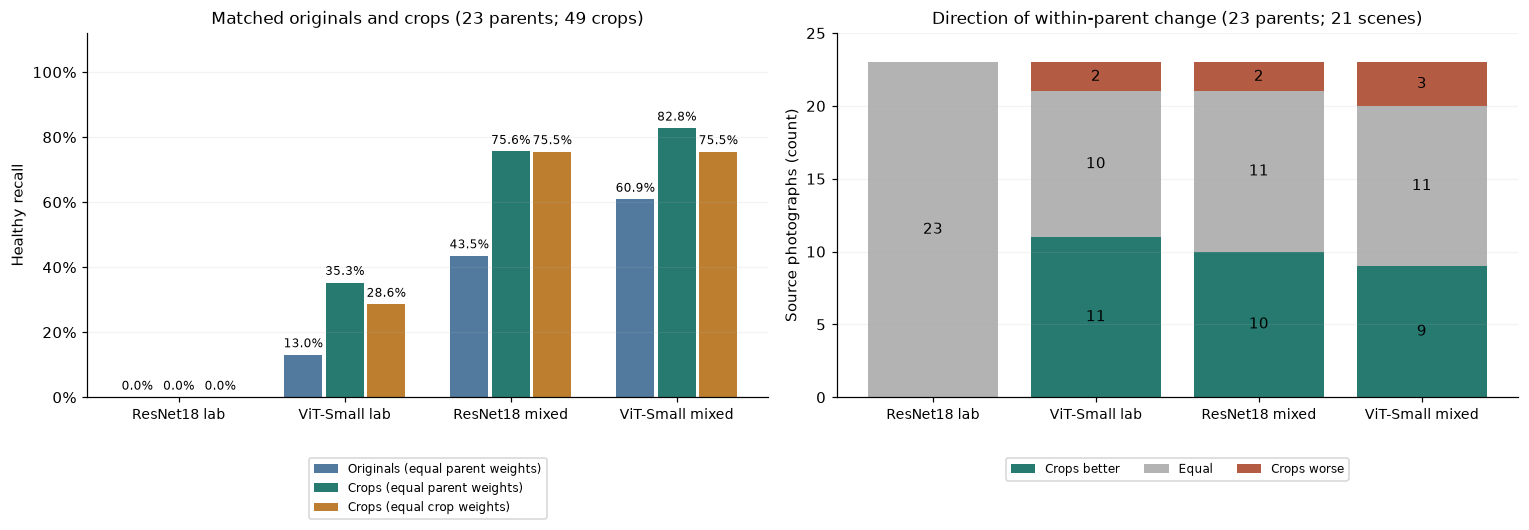

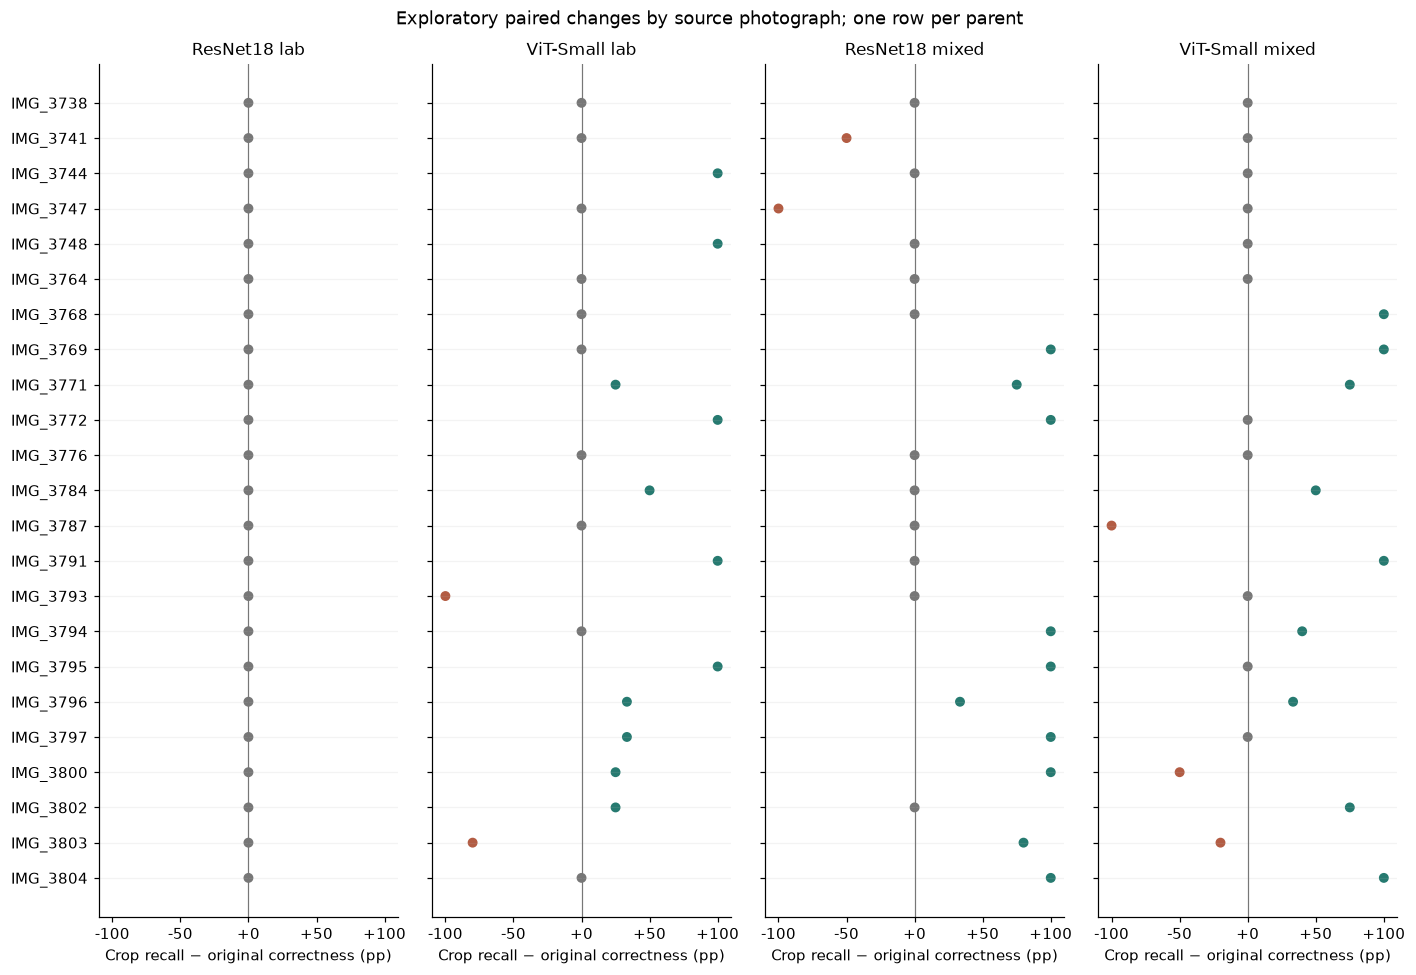

In [16]:
paired_parent_rows = []
for (key, filename, checksum), group in exploratory_predictions.groupby(["model_key", "parent_filename", "parent_sha256"], sort=True):
    original = group.loc[group.record_type.eq("original")]
    children = group.loc[group.record_type.eq("crop")]
    assert len(original) == 1 and len(children) >= 1 and children.image_id.is_unique
    original = original.iloc[0]
    original_correct, crop_recall = int(original.correct), float(children.correct.mean())
    delta = crop_recall - original_correct
    diseases = children.loc[~children.correct].predicted_label.value_counts().sort_index().to_dict()
    paired_parent_rows.append({"model_key": key, "model": MODEL_SPECS[key]["model"], "parent_filename": filename,
        "parent_image_id": original.parent_image_id, "parent_sha256": checksum, "plant_id": original.plant_id,
        "scene_group_id": original.scene_group_id, "original_image_id": original.image_id,
        "original_prediction": original.predicted_label, "original_confidence": original.confidence,
        "original_correct": original_correct, "original_disease_alarm_label": "" if original_correct else original.predicted_label,
        "original_prediction_origin": original.prediction_origin,
        "accepted_crops": len(children), "crop_ids": " | ".join(sorted(children.image_id)),
        "correct_crops": int(children.correct.sum()), "crop_healthy_recall": crop_recall,
        "parent_average_crop_correctness": crop_recall, "per_parent_change": delta,
        "cropping_outcome": "better" if delta > 0 else ("worse" if delta < 0 else "equal"),
        "crop_false_disease_distribution": json.dumps(diseases, sort_keys=True),
        "original_and_any_crop_wrong": (not bool(original_correct)) and (~children.correct).any(),
        "original_and_all_crops_wrong": (not bool(original_correct)) and (~children.correct).all(),
        "shared_wrong_disease_label": (not bool(original_correct)) and children.predicted_label.eq(original.predicted_label).any()})
exploratory_parent_summary = pd.DataFrame(paired_parent_rows)
assert len(exploratory_parent_summary) == 92
exploratory_parent_summary.to_csv(OUTPUT_ROOT / "paired_parent_summary.csv", index=False)
comparison_rows = []
for key, group in exploratory_parent_summary.groupby("model_key", sort=False):
    better, worse, equal = [int(group.cropping_outcome.eq(outcome).sum()) for outcome in ("better", "worse", "equal")]
    assert better + worse + equal == 23 and group.accepted_crops.sum() == 49
    scene = group.groupby("scene_group_id").agg(original_recall=("original_correct", "mean"),
        crop_parent_recall=("crop_healthy_recall", "mean"))
    comparison_rows.append({"model_key": key, "model": MODEL_SPECS[key]["model"], "parents": len(group),
        "recorded_scene_groups": group.scene_group_id.nunique(), "accepted_crops": int(group.accepted_crops.sum()),
        "original_correct": int(group.original_correct.sum()), "original_healthy_recall": group.original_correct.mean(),
        "crop_correct": int(group.correct_crops.sum()), "crop_level_healthy_recall": group.correct_crops.sum()/group.accepted_crops.sum(),
        "parent_macro_crop_recall": group.crop_healthy_recall.mean(), "parent_macro_change": group.per_parent_change.mean(),
        "parents_better": better, "parents_worse": worse, "parents_equal": equal,
        "parents_original_and_any_crop_wrong": int(group.original_and_any_crop_wrong.sum()),
        "parents_original_and_all_crops_wrong": int(group.original_and_all_crops_wrong.sum()),
        "parents_sharing_wrong_disease_label": int(group.shared_wrong_disease_label.sum()),
        "equal_scene_original_recall": scene.original_recall.mean(),
        "equal_scene_parent_macro_crop_recall": scene.crop_parent_recall.mean()})
paired_model_comparison = pd.DataFrame(comparison_rows).set_index("model_key").loc[list(MODEL_SPECS)].reset_index()
paired_model_comparison.to_csv(OUTPUT_ROOT / "paired_model_comparison.csv", index=False)
readout = paired_model_comparison.assign(model_name=paired_model_comparison.model_key.map(SHORT_NAMES)).set_index("model_name")
readout["parent_macro_change"] *= 100
display(readout[["original_correct", "original_healthy_recall", "crop_correct", "crop_level_healthy_recall",
                 "parent_macro_crop_recall", "parent_macro_change"]].rename(columns={
    "original_correct":"Original correct / 23", "original_healthy_recall":"Original recall",
    "crop_correct":"Crop correct / 49", "crop_level_healthy_recall":"Crop recall",
    "parent_macro_crop_recall":"Parent-macro crop recall", "parent_macro_change":"Paired change (pp)"}).style.format({
    "Original recall":"{:.1%}","Crop recall":"{:.1%}","Parent-macro crop recall":"{:.1%}","Paired change (pp)":"{:+.1f}"}))
display(readout[["parents_better","parents_worse","parents_equal"]].rename(columns=lambda s:s.replace("_"," ").title()))
# Full parent-level predictions and false disease labels remain available in the saved CSV.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(4)
for i, (field, label, color) in enumerate([
    ("original_healthy_recall", "Originals (equal parent weights)", "#527a9f"),
    ("parent_macro_crop_recall", "Crops (equal parent weights)", "#267a70"),
    ("crop_level_healthy_recall", "Crops (equal crop weights)", "#bd7f2f")]):
    values = paired_model_comparison[field]
    bars = axes[0].bar(x+(i-1)*.25, values, width=.23, label=label, color=color)
    axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in values], fontsize=8, padding=3)
axes[0].set(xticks=x, xticklabels=SHORT_NAMES.values(), ylabel="Healthy recall", ylim=(0,1.12),
            title="Matched originals and crops (23 parents; 49 crops)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc="upper center", bbox_to_anchor=(.5,-.15), fontsize=8)
bottom = np.zeros(4)
for column, label, color in [("parents_better","Crops better","#267a70"),
                             ("parents_equal","Equal","#b3b3b3"),("parents_worse","Crops worse","#b35c43")]:
    values = paired_model_comparison[column].to_numpy()
    bars = axes[1].bar(x, values, bottom=bottom, color=color, label=label)
    for i, v in enumerate(values):
        if v:axes[1].text(i, bottom[i]+v/2, str(v), ha="center",va="center",fontsize=10)
    bottom += values
axes[1].set(xticks=x, xticklabels=SHORT_NAMES.values(), ylabel="Source photographs (count)", ylim=(0,25),
            title="Direction of within-parent change (23 parents; 21 scenes)")
axes[1].legend(loc="upper center", bbox_to_anchor=(.5,-.15), fontsize=8, ncol=3)
for ax in axes:ax.grid(axis="y",alpha=.15);ax.tick_params(axis="x",labelsize=9)
fig.tight_layout();fig.savefig(OUTPUT_ROOT / "figures/paired_healthy_recognition.png",dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)
fig, axes = plt.subplots(1,4,figsize=(13,9),sharey=True)
parent_order = sorted(exploratory_parent_summary.parent_filename.unique())
for ax,key in zip(axes,MODEL_SPECS):
    rows = exploratory_parent_summary.loc[exploratory_parent_summary.model_key.eq(key)].set_index("parent_filename").loc[parent_order]
    ax.axvline(0,color="#777777",lw=.8)
    ax.scatter(rows.per_parent_change,np.arange(23),c=["#267a70" if d>0 else "#b35c43" if d<0 else "#777777" for d in rows.per_parent_change],s=30)
    ax.set(xlim=(-1.1,1.1),xticks=[-1,-.5,0,.5,1],xlabel="Crop recall − original correctness (pp)",title=SHORT_NAMES[key])
    ax.xaxis.set_major_formatter(lambda value, position: f"{100*value:+.0f}");ax.grid(axis="y",alpha=.15)
axes[0].set(yticks=np.arange(23),yticklabels=[p.replace('.JPG','') for p in parent_order]);axes[0].invert_yaxis()
fig.suptitle("Exploratory paired changes by source photograph; one row per parent",fontsize=12)
fig.tight_layout();fig.savefig(OUTPUT_ROOT / "figures/paired_parent_changes.png",dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)


## Error analysis

### Baseline-to-mixed changes and cross-architecture disagreement

A recovered image is incorrect at baseline and correct for the corresponding mixed model; a lost image changes in the opposite direction. Each comparison pairs the same image IDs. ResNet18's contrast includes geometric initialization as well as mixed-domain adaptation and does not isolate either stage.

The first three correctness-agreement categories partition the 57 images. Mixed-model label disagreement is a separate, overlapping measure.

In [17]:
paired = healthy.copy().set_index("image_id")
for key, frame in prediction_frames.items():
    indexed = frame.set_index("image_id").loc[paired.index]
    for column in ("predicted_label", "confidence", "correct"):
        paired[f"{key}_{column}"] = indexed[column]
paired = paired.reset_index()
change_rows = []
for arch in ("resnet", "vit"):
    baseline, mixed = f"{arch}_lab", f"{arch}_mixed"
    paired[f"{arch}_recovered"] = ~paired[f"{baseline}_correct"] & paired[f"{mixed}_correct"]
    paired[f"{arch}_lost"] = paired[f"{baseline}_correct"] & ~paired[f"{mixed}_correct"]
    for subset in ("All Healthy", *SUBSETS):
        group = paired if subset == "All Healthy" else (paired.loc[paired.is_crop] if subset == "All crops"
                                                       else paired.loc[paired.analysis_subset.eq(subset)])
        recovered, lost = int(group[f"{arch}_recovered"].sum()), int(group[f"{arch}_lost"].sum())
        assert recovered-lost == int(group[f"{mixed}_correct"].sum()-group[f"{baseline}_correct"].sum())
        change_rows.append({"architecture": arch, "subset": subset, "images": len(group),
                            "recovered": recovered, "lost": lost, "net_correct": recovered-lost})
changes = pd.DataFrame(change_rows)
changes.to_csv(OUTPUT_ROOT / "adaptation_changes.csv", index=False)
paired["all_models_wrong"] = ~paired[[f"{k}_correct" for k in MODEL_SPECS]].any(axis=1)
paired["all_models_correct"] = paired[[f"{k}_correct" for k in MODEL_SPECS]].all(axis=1)
paired["mixed_label_disagreement"] = paired.resnet_mixed_predicted_label.ne(paired.vit_mixed_predicted_label)
paired.to_csv(OUTPUT_ROOT / "cross_model_image_comparison.csv", index=False)
paired.loc[paired.all_models_wrong].to_csv(OUTPUT_ROOT / "all_models_incorrect.csv", index=False)
display(changes.loc[changes.subset.eq("All Healthy")].set_index("architecture"))
agreement = pd.DataFrame({"Outcome": ["All four correct", "All four incorrect", "Other correctness patterns", "Mixed CNN–ViT label disagreement"],
    "Images": [int(paired.all_models_correct.sum()), int(paired.all_models_wrong.sum()),
               int((~paired.all_models_correct & ~paired.all_models_wrong).sum()),
               int(paired.mixed_label_disagreement.sum())]})
display(agreement)
agreement.to_csv(OUTPUT_ROOT / "model_agreement.csv", index=False)
# The first three agreement rows partition the sample; label disagreement is a separate overlapping measure.
shared = paired.loc[paired.all_models_wrong]
display(shared[["image_id", "original_filename", "analysis_subset"] +
               [f"{key}_predicted_label" for key in MODEL_SPECS]]
        .rename(columns={f"{key}_predicted_label": name for key,name in SHORT_NAMES.items()})
        .set_index("image_id"))

,subset,images,recovered,lost,net_correct
architecture,,,,,
resnet,All Healthy,57,44,0,44
vit,All Healthy,57,28,0,28


,Outcome,Images
0,All four correct,0
1,All four incorrect,4
2,Other correctness patterns,53
3,Mixed CNN–ViT label disagreement,23


,original_filename,analysis_subset,ResNet18 lab,ViT-Small lab,ResNet18 mixed,ViT-Small mixed
image_id,,,,,,
HLV3_0032,IMG_3771.JPG,Newly approved crops,Early Blight,Septoria Leaf Spot,Early Blight,Bacterial Spot
HLV3_0083,IMG_3796.JPG,Newly approved crops,Early Blight,Bacterial Spot,Late Blight,Bacterial Spot
HLV3_0085,IMG_3796.JPG,Newly approved crops,Late Blight,Late Blight,Late Blight,Bacterial Spot
HLV3_0128,IMG_3802.JPG,Newly approved crops,Late Blight,Septoria Leaf Spot,Late Blight,Bacterial Spot


### Representative image cases

The selected gallery includes persistent shared errors, adaptation recoveries, CNN–ViT disagreement and the valid original–crop pair, where available. Selection is deterministic and illustrative rather than a random sample. Model outputs are shown without diagnosing visual symptoms or changing human labels.

Photographs remain in local gallery files; the notebook stores only relative links and prediction tables, avoiding embedded external image pixels.

In [18]:
selected_ids, selection_reasons = [], {}
def add_cases(frame, reason, limit):
    added = 0
    for image_id in frame.sort_values("image_id").image_id:
        if image_id not in selected_ids and added < limit:
            selected_ids.append(image_id);selection_reasons[image_id] = reason;added += 1
add_cases(paired.loc[paired.all_models_wrong], "Incorrect for all four models", 2)
add_cases(paired.loc[paired.resnet_recovered | paired.vit_recovered], "Corrected by mixed-domain adaptation", 2)
add_cases(paired.loc[paired.mixed_label_disagreement], "Mixed CNN–ViT label disagreement", 2)
for image_id in ["SC_0011", "HLV3_0064"]:
    if image_id not in selected_ids:selected_ids.append(image_id)
    selection_reasons[image_id] = "Valid evaluated original–crop pair"
selected = paired.set_index("image_id").loc[selected_ids].reset_index()
selected["selection_reason"] = selected.image_id.map(selection_reasons)
selected.to_csv(OUTPUT_ROOT / "selected_examples.csv", index=False)
fig, axes = plt.subplots(int(np.ceil(len(selected)/3)), 3, figsize=(15, 4.6*int(np.ceil(len(selected)/3))))
for ax in np.asarray(axes).flat:ax.axis("off")
for ax, row in zip(np.asarray(axes).flat, selected.itertuples()):
    with Image.open(DATA_ROOT / row.image_path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    labels = [f"{SHORT_NAMES[k]}: {getattr(row, k+'_predicted_label')} ({getattr(row, k+'_confidence'):.2f})"
              for k in MODEL_SPECS]
    ax.set_title(row.image_id + " — " + row.original_filename + "\n" + "\n".join(labels), fontsize=9)
fig.suptitle("Selected human-labeled Healthy cases; scores are uncalibrated", fontsize=12)
fig.tight_layout();fig.savefig(OUTPUT_ROOT / "figures/selected_healthy_cases.png", dpi=130,bbox_inches="tight");plt.close(fig)
relative_gallery = os.path.relpath(OUTPUT_ROOT / "figures/selected_healthy_cases.png", PROJECT_ROOT / "notebooks")
display(HTML(f'<p><a href="{escape(quote(relative_gallery, safe="/"))}">Open selected Healthy image gallery</a></p>'))
example_table = selected[["image_id", "original_filename", "analysis_subset", "selection_reason"]].copy()
for key, short in SHORT_NAMES.items():
    example_table[short] = selected[f"{key}_predicted_label"] + " (" + selected[f"{key}_confidence"].map(lambda x: f"{x:.2f}") + ")"
display(example_table.set_index("image_id"))

,original_filename,analysis_subset,selection_reason,ResNet18 lab,ViT-Small lab,ResNet18 mixed,ViT-Small mixed
image_id,,,,,,,
HLV3_0032,IMG_3771.JPG,Newly approved crops,Incorrect for all four models,Early Blight (0.77),Septoria Leaf Spot (0.42),Early Blight (0.48),Bacterial Spot (0.58)
HLV3_0083,IMG_3796.JPG,Newly approved crops,Incorrect for all four models,Early Blight (0.60),Bacterial Spot (0.50),Late Blight (0.36),Bacterial Spot (0.67)
HLV3_0008,IMG_3741.JPG,Newly approved crops,Corrected by mixed-domain adaptation,Late Blight (1.00),Early Blight (0.91),Healthy (0.76),Healthy (0.55)
HLV3_0009,IMG_3741.JPG,Newly approved crops,Corrected by mixed-domain adaptation,Early Blight (0.70),Early Blight (0.62),Late Blight (0.40),Healthy (0.77)
HLV3_0025,IMG_3768.JPG,Newly approved crops,Mixed CNN–ViT label disagreement,Late Blight (1.00),Late Blight (0.70),Late Blight (0.71),Healthy (0.40)
HLV3_0054,IMG_3784.JPG,Newly approved crops,Mixed CNN–ViT label disagreement,Late Blight (0.54),Early Blight (0.74),Healthy (0.90),Early Blight (0.40)
SC_0011,IMG_3793.JPG,Original photographs,Valid evaluated original–crop pair,Early Blight (0.98),Healthy (0.39),Healthy (0.94),Healthy (0.89)
HLV3_0064,IMG_3793.JPG,Newly approved crops,Valid evaluated original–crop pair,Early Blight (0.75),Septoria Leaf Spot (0.37),Healthy (0.89),Healthy (0.85)


## Discussion and Conclusion

The original 57-image evaluation is reproduced without changing its predictions. The separate exploratory extension compares the 23 verified source photographs with their own 49 accepted crops, weighting each parent equally in the main paired summary. Neither experiment establishes a causal cropping benefit or independent plant-level generalization.

In [19]:
discussion = []
for arch, title in (("resnet", "ResNet18"), ("vit", "ViT-Small")):
    change = changes.loc[changes.architecture.eq(arch) & changes.subset.eq("All Healthy")].iloc[0]
    discussion.append(f"**{title}:** adaptation recovers {int(change.recovered)} images and loses {int(change.lost)}, "
                      f"for a net change of {int(change.net_correct):+d}/57. This is an observed configuration difference, "
                      "not a causal estimate of adaptation alone.")
for key in MODEL_SPECS:
    table = subset_metrics.loc[subset_metrics.model_key.eq(key)].set_index("subset")
    o, h, n, c = [table.loc[s] for s in SUBSETS]
    discussion.append(f"**{SHORT_NAMES[key]}:** originals {int(o.correct)}/8, historical crops {int(h.correct)}/7, "
                      f"new crops {int(n.correct)}/42 and all crops {int(c.correct)}/49. "
                      f"The unpaired crop–original recall difference is {100*(c.healthy_recall-o.healthy_recall):+.1f} percentage points.")
pair_text = "; ".join(f"{SHORT_NAMES[r.model_key]}: {r.original_prediction} → "
                      f"{int(r.crop_correct)}/{r.crops} crop correct ({r.cropping_outcome})"
                      for r in paired_comparison.itertuples())
discussion.append("**Direct pair, IMG_3793:** " + pair_text + ". This single existing pair cannot establish a general cropping benefit; the separate extension provides wider paired coverage.")
discussion.append(f"**Shared failures:** {int(paired.all_models_wrong.sum())}/57 images remain incorrect for every model. "
                  "These failures motivate further model analysis, not relabeling of the source photographs.")
for key in ("resnet_mixed", "vit_mixed"):
    patterns = []
    for subset in ("Historical crops", "Newly approved crops"):
        errors = disease_distribution.loc[disease_distribution.model_key.eq(key) &
            disease_distribution.subset.eq(subset) & disease_distribution["count"].gt(0)]
        destinations = ", ".join(f"{r.predicted_disease} {r.count}" for r in errors.itertuples()) or "no false disease alarms"
        patterns.append(f"{subset.lower()}: {destinations}")
    discussion.append(f"**{SHORT_NAMES[key]} crop-error destinations:** " + "; ".join(patterns) +
                      ". These selected crop types differ in composition, so the patterns do not isolate a framing effect.")
w = weighted_summary.loc[weighted_summary.subset.eq("All crops")].set_index("model_key")
discussion.append(f"**Crop weighting:** both mixed models recognize 37/49 crops (75.5%) with equal crop weights. "
    f"Equal-parent recall is {w.loc['resnet_mixed','equal_parent_recall']:.1%} for ResNet18 and "
    f"{w.loc['vit_mixed','equal_parent_recall']:.1%} for ViT-Small across 23 parents; "
    f"equal-scene parent-balanced recall is {w.loc['resnet_mixed','equal_scene_parent_balanced_recall']:.1%} "
    f"and {w.loc['vit_mixed','equal_scene_parent_balanced_recall']:.1%}, respectively. "
    "The descriptive comparison therefore depends on the unit of weighting.")

discussion.append("**Paired extension:** the source-matched exploratory findings below supplement these preserved 57-image results. No inference on absent originals is imputed.")
discussion.append("**Scope:** human annotations are not laboratory confirmation; 42 new crops are not 42 independent plants. "
                  "The 49 crops span 23 source photographs and 21 recorded scenes. Parent/scene weighting addresses unequal "
                  "crop counts but cannot remove selection bias or all dependence. Mixed models were selected on Field Dev. "
                  "Softmax scores are uncalibrated, and no inference on the 46 online disease images is performed here.")
display(Markdown("\n\n".join(discussion)))
findings = "# Healthy field and leaf-crop evaluation — Tomato Field Evaluation v2\n\n" + "\n\n".join(notes + discussion)
(OUTPUT_ROOT / "findings.md").write_text(findings)

**ResNet18:** adaptation recovers 44 images and loses 0, for a net change of +44/57. This is an observed configuration difference, not a causal estimate of adaptation alone.

**ViT-Small:** adaptation recovers 28 images and loses 0, for a net change of +28/57. This is an observed configuration difference, not a causal estimate of adaptation alone.

**ResNet18 lab:** originals 0/8, historical crops 0/7, new crops 0/42 and all crops 0/49. The unpaired crop–original recall difference is +0.0 percentage points.

**ViT-Small lab:** originals 1/8, historical crops 4/7, new crops 10/42 and all crops 14/49. The unpaired crop–original recall difference is +16.1 percentage points.

**ResNet18 mixed:** originals 7/8, historical crops 5/7, new crops 32/42 and all crops 37/49. The unpaired crop–original recall difference is -12.0 percentage points.

**ViT-Small mixed:** originals 6/8, historical crops 7/7, new crops 30/42 and all crops 37/49. The unpaired crop–original recall difference is +0.5 percentage points.

**Direct pair, IMG_3793:** ResNet18 lab: Early Blight → 0/1 crop correct (unchanged); ViT-Small lab: Healthy → 0/1 crop correct (worsened); ResNet18 mixed: Healthy → 1/1 crop correct (unchanged); ViT-Small mixed: Healthy → 1/1 crop correct (unchanged). This single existing pair cannot establish a general cropping benefit; the separate extension provides wider paired coverage.

**Shared failures:** 4/57 images remain incorrect for every model. These failures motivate further model analysis, not relabeling of the source photographs.

**ResNet18 mixed crop-error destinations:** historical crops: Late Blight 2; newly approved crops: Early Blight 1, Late Blight 8, Bacterial Spot 1. These selected crop types differ in composition, so the patterns do not isolate a framing effect.

**ViT-Small mixed crop-error destinations:** historical crops: no false disease alarms; newly approved crops: Early Blight 4, Late Blight 2, Bacterial Spot 6. These selected crop types differ in composition, so the patterns do not isolate a framing effect.

**Crop weighting:** both mixed models recognize 37/49 crops (75.5%) with equal crop weights. Equal-parent recall is 75.6% for ResNet18 and 82.8% for ViT-Small across 23 parents; equal-scene parent-balanced recall is 78.0% and 81.1%, respectively. The descriptive comparison therefore depends on the unit of weighting.

**Paired extension:** the source-matched exploratory findings below supplement these preserved 57-image results. No inference on absent originals is imputed.

**Scope:** human annotations are not laboratory confirmation; 42 new crops are not 42 independent plants. The 49 crops span 23 source photographs and 21 recorded scenes. Parent/scene weighting addresses unequal crop counts but cannot remove selection bias or all dependence. Mixed models were selected on Field Dev. Softmax scores are uncalibrated, and no inference on the 46 online disease images is performed here.

3206

In [20]:
paired_notes = [
    "**Mapping audit:** all 49 crops have verified source filenames, byte hashes, coordinates and review provenance. "
    "They derive from 23 photographs in 21 recorded scene groups. Only IMG_3793 is among the eight evaluation originals. "
    "The initial one-pair result was therefore a coverage limitation, not an identifier-matching error.",
    "**Exploratory coverage:** 22 additional, explicitly human-labeled Healthy source photographs were evaluated with the "
    "same four frozen checkpoints. The existing IMG_3793 original and all 49 crop predictions were reused. "
    "The original 57-image evaluation and dataset v2 are unchanged."
]
for r in paired_model_comparison.itertuples():
    paired_notes.append(f"**{SHORT_NAMES[r.model_key]}:** originals {r.original_correct}/{r.parents} "
        f"({r.original_healthy_recall:.1%}); crops {r.crop_correct}/{r.accepted_crops} "
        f"({r.crop_level_healthy_recall:.1%}); equal-parent crop recall {r.parent_macro_crop_recall:.1%}. "
        f"The paired parent-macro change is {100*r.parent_macro_change:+.1f} percentage points: "
        f"{r.parents_better} parents better, {r.parents_worse} worse and {r.parents_equal} equal. "
        f"Originals and at least one crop are both incorrect for {r.parents_original_and_any_crop_wrong} parents; "
        f"all crops and their original are incorrect for {r.parents_original_and_all_crops_wrong}.")
for arch,title in (("resnet","ResNet18"),("vit","ViT-Small")):
    table = paired_model_comparison.set_index("model_key")
    b,m = table.loc[f"{arch}_lab"],table.loc[f"{arch}_mixed"]
    paired_notes.append(f"**{title} configuration comparison:** original recall {b.original_healthy_recall:.1%} → "
        f"{m.original_healthy_recall:.1%}, and parent-macro crop recall {b.parent_macro_crop_recall:.1%} → "
        f"{m.parent_macro_crop_recall:.1%} from laboratory baseline to mixed model. "
        + ("The CNN contrast also includes geometric initialization." if arch=="resnet" else "The comparison remains descriptive for these fixed checkpoints."))
positive_models = [SHORT_NAMES[r.model_key] for r in paired_model_comparison.itertuples() if r.parent_macro_change > 0]
paired_notes.append("**Paired synthesis:** cropping has higher equal-parent Healthy recall for " + ", ".join(positive_models) +
    ", while the ResNet18 laboratory baseline remains incorrect throughout. The three positive mean changes each include "
    "parents that become worse, so the benefit is not uniform. Scene-balanced sensitivity summaries retain these directions. "
    "Both mixed models outperform their laboratory baselines on the matched originals and parent-averaged crops.")

paired_notes.append("**Interpretation:** the better/worse/equal counts show whether an average change is shared across parents. "
    "A positive mean alone would not establish a consistent benefit. These descriptive comparisons use selected, correlated "
    "sources already inspected in exploratory analyses; they are not a newly independent test. Cropping changes framing, "
    "relative leaf size, visible context and sometimes the target leaf. It does not isolate the causal effect of input resolution.")
paired_notes.append("**Limits:** each parent contributes one paired mean; parents within a recorded scene may still be related. "
    "Recorded plant IDs are not a verified count of independent physical plants. Healthy labels remain human annotations, "
    "not laboratory-confirmed diagnoses. Softmax scores are uncalibrated. No training, model selection or threshold tuning was performed.")
display(Markdown("\n\n".join(paired_notes)))
(OUTPUT_ROOT / "paired_analysis_findings.md").write_text(
    "# Exploratory Paired Original–Crop Evaluation\n\n" + "\n\n".join(paired_notes),encoding="utf-8")
# Label-level shared errors, retained without relabeling any photograph.
display(exploratory_parent_summary.groupby("model_key",sort=False)[[
    "original_and_any_crop_wrong","original_and_all_crops_wrong","shared_wrong_disease_label"]].sum().rename(index=SHORT_NAMES))


**Mapping audit:** all 49 crops have verified source filenames, byte hashes, coordinates and review provenance. They derive from 23 photographs in 21 recorded scene groups. Only IMG_3793 is among the eight evaluation originals. The initial one-pair result was therefore a coverage limitation, not an identifier-matching error.

**Exploratory coverage:** 22 additional, explicitly human-labeled Healthy source photographs were evaluated with the same four frozen checkpoints. The existing IMG_3793 original and all 49 crop predictions were reused. The original 57-image evaluation and dataset v2 are unchanged.

**ResNet18 lab:** originals 0/23 (0.0%); crops 0/49 (0.0%); equal-parent crop recall 0.0%. The paired parent-macro change is +0.0 percentage points: 0 parents better, 0 worse and 23 equal. Originals and at least one crop are both incorrect for 23 parents; all crops and their original are incorrect for 23.

**ViT-Small lab:** originals 3/23 (13.0%); crops 14/49 (28.6%); equal-parent crop recall 35.3%. The paired parent-macro change is +22.2 percentage points: 11 parents better, 2 worse and 10 equal. Originals and at least one crop are both incorrect for 15 parents; all crops and their original are incorrect for 9.

**ResNet18 mixed:** originals 10/23 (43.5%); crops 37/49 (75.5%); equal-parent crop recall 75.6%. The paired parent-macro change is +32.1 percentage points: 10 parents better, 2 worse and 11 equal. Originals and at least one crop are both incorrect for 6 parents; all crops and their original are incorrect for 3.

**ViT-Small mixed:** originals 14/23 (60.9%); crops 37/49 (75.5%); equal-parent crop recall 82.8%. The paired parent-macro change is +21.9 percentage points: 9 parents better, 3 worse and 11 equal. Originals and at least one crop are both incorrect for 5 parents; all crops and their original are incorrect for 0.

**ResNet18 configuration comparison:** original recall 0.0% → 43.5%, and parent-macro crop recall 0.0% → 75.6% from laboratory baseline to mixed model. The CNN contrast also includes geometric initialization.

**ViT-Small configuration comparison:** original recall 13.0% → 60.9%, and parent-macro crop recall 35.3% → 82.8% from laboratory baseline to mixed model. The comparison remains descriptive for these fixed checkpoints.

**Paired synthesis:** cropping has higher equal-parent Healthy recall for ViT-Small lab, ResNet18 mixed, ViT-Small mixed, while the ResNet18 laboratory baseline remains incorrect throughout. The three positive mean changes each include parents that become worse, so the benefit is not uniform. Scene-balanced sensitivity summaries retain these directions. Both mixed models outperform their laboratory baselines on the matched originals and parent-averaged crops.

**Interpretation:** the better/worse/equal counts show whether an average change is shared across parents. A positive mean alone would not establish a consistent benefit. These descriptive comparisons use selected, correlated sources already inspected in exploratory analyses; they are not a newly independent test. Cropping changes framing, relative leaf size, visible context and sometimes the target leaf. It does not isolate the causal effect of input resolution.

**Limits:** each parent contributes one paired mean; parents within a recorded scene may still be related. Recorded plant IDs are not a verified count of independent physical plants. Healthy labels remain human annotations, not laboratory-confirmed diagnoses. Softmax scores are uncalibrated. No training, model selection or threshold tuning was performed.

,original_and_any_crop_wrong,original_and_all_crops_wrong,shared_wrong_disease_label
model_key,,,
ResNet18 lab,23,23,17
ResNet18 mixed,6,3,3
ViT-Small lab,15,9,9
ViT-Small mixed,5,0,1


### Reproducibility checks

Metrics are independently recalculated from the saved prediction CSVs. The 15 reused Healthy v1 images are also compared with the fixed Notebook 11 predictions. Checkpoint identity, transform configuration, source metadata and input integrity are retained with the results.

In [21]:
saved = pd.read_csv(OUTPUT_ROOT / "image_level_predictions.csv", keep_default_na=False)
assert len(saved) == 228 and saved.source.eq("self_collected").all() and saved.ground_truth_label.eq("Healthy").all()
assert not saved.duplicated(["model_key", "image_id"]).any()
assert saved.correct.eq(saved.predicted_label_id.eq(saved.label_id)).all()
probability_columns = [f"probability_label_{i}" for i in LABEL_IDS]
assert np.allclose(saved[probability_columns].sum(axis=1), 1, atol=1e-6)
assert np.array_equal(saved[probability_columns].to_numpy().argmax(axis=1), saved.predicted_label_id)
assert np.allclose(saved[probability_columns].max(axis=1), saved.confidence)
metric_checks = []
for row in subset_metrics.itertuples():
    frame = saved.loc[saved.model_key.eq(row.model_key)]
    group = frame.loc[frame.is_crop] if row.subset == "All crops" else frame.loc[frame.analysis_subset.eq(row.subset)]
    assert len(group) == row.images
    assert int(group.predicted_label_id.eq(0).sum()) == row.correct
    assert np.isclose(row.healthy_recall, group.predicted_label_id.eq(0).mean())
    assert np.isclose(row.false_disease_alarm_rate, group.predicted_label_id.ne(0).mean())
    assert sum(getattr(row, "predicted_"+name.lower().replace(" ", "_")) for name in CLASS_NAMES) == len(group)
    metric_checks.append({"model_key": row.model_key, "subset": row.subset, "saved_prediction_metrics_match": True})
pd.DataFrame(metric_checks).to_csv(OUTPUT_ROOT / "audit/metric_validation.csv", index=False)
# Recalculate equal-parent and equal-scene estimates directly from the saved image records.
for row in weighted_summary.itertuples():
    frame = saved.loc[saved.model_key.eq(row.model_key) & saved.is_crop]
    if row.subset != "All crops":frame = frame.loc[frame.analysis_subset.eq(row.subset)]
    p = frame.groupby(["scene_group_id", "parent_image_id"]).correct.mean()
    assert len(p) == row.parents and np.isclose(p.mean(), row.equal_parent_recall)
    assert np.isclose(p.groupby(level=0).mean().mean(), row.equal_scene_parent_balanced_recall)
reference_checks = []
for key, frame in prediction_frames.items():
    previous = pd.read_csv(REFERENCE_RUN / f"predictions_{key}.csv").set_index("image_id")
    reused_ids = frame.loc[frame.image_id.isin(previous.index), "image_id"]
    assert len(reused_ids) == 15
    current, prior = frame.set_index("image_id").loc[reused_ids], previous.loc[reused_ids]
    assert current.sha256.eq(prior.sha256).all()
    assert np.array_equal(current.predicted_label_id, prior.predicted_label_id)
    difference = float(np.abs(current[probability_columns].to_numpy()-prior[probability_columns].to_numpy()).max())
    assert difference <= 2e-5, (key, difference)
    reference_checks.append({"model_key": key, "reused_healthy_images": len(reused_ids),
                             "identical_predicted_labels": True, "max_probability_difference": difference})
pd.DataFrame(reference_checks).to_csv(OUTPUT_ROOT / "audit/notebook11_reproduction.csv", index=False)
assert all(sha256_file(path) == digest for path, digest in PROTECTED.items()), "Protected input changed"
protocol = {"task": "Notebook 13 — preserved Healthy evaluation and separate exploratory paired extension", "run_id": RUN_ID,
    "dataset_id": "tomato_field_eval_v2", "manifest_sha256": MANIFEST_SHA256,
    "dataset_readme_sha256": DATASET_README_SHA256, "complete_four_model_evaluation": True,
    "images_per_model": 57, "predictions": 228, "subsets": SUBSETS,
    "healthy_source_photographs": int(healthy.parent_image_id.nunique()),
    "healthy_recorded_scene_groups": int(healthy.scene_group_id.nunique()),
    "crop_source_photographs": 23, "crop_recorded_scene_groups": 21,
    "directly_paired_parents": int(paired_comparison.parent_image_id.nunique()),
    "reference_notebook11_run": str(REFERENCE_RUN.relative_to(PROJECT_ROOT)),
    "reference_protocol_sha256": sha256_file(REFERENCE_RUN / "evaluation_protocol.json"),
    "checkpoints_and_preprocessing": provenance_records, "split_sha256": SPLIT_HASHES,
    "device": str(DEVICE), "versions": VERSIONS, "python": platform.python_version(), "seed": 42,
    "inference": "float32, eval, inference_mode, five-class argmax; no TTA",
    "confidence": "uncalibrated maximum softmax", "training_or_tuning_performed": False,
    "online_disease_inference_performed": False, "original_57_inference_performed": False,
    "base_evaluation_run": str(BASE_EVALUATION_RUN.relative_to(PROJECT_ROOT)), "external_photographs_embedded_in_notebook": False,
    "protected_files_sha256": {str(p): h for p,h in PROTECTED.items()},
    "prediction_csv_sha256": sha256_file(OUTPUT_ROOT / "image_level_predictions.csv"),
    "summary_csv_sha256": sha256_file(OUTPUT_ROOT / "model_summary.csv"),
    "completed_at_utc": datetime.now(timezone.utc).isoformat()}
(OUTPUT_ROOT / "audit/evaluation_protocol.json").write_text(json.dumps(protocol, indent=2, default=str))
display(Markdown(f"The original four-model evaluation on 57 Healthy images was reproduced from saved predictions. "
                 f"Saved-prediction metrics and protected-input checks passed. Results: `{OUTPUT_ROOT.relative_to(PROJECT_ROOT)}`."))

The original four-model evaluation on 57 Healthy images was reproduced from saved predictions. Saved-prediction metrics and protected-input checks passed. Results: `outputs/healthy_field_evaluation/tomato_field_eval_v2/paired_20261126_105328_eddcf985`.

In [22]:
# Reproduce every parent and model summary directly from the new saved prediction table.
saved_pairs = pd.read_csv(OUTPUT_ROOT / "paired_original_crop_predictions.csv",keep_default_na=False)
saved_parent = pd.read_csv(OUTPUT_ROOT / "paired_parent_summary.csv",keep_default_na=False)
saved_models = pd.read_csv(OUTPUT_ROOT / "paired_model_comparison.csv",keep_default_na=False)
assert len(saved_pairs) == 288 and saved_pairs.ground_truth_label.eq("Healthy").all()
assert not saved_pairs.duplicated(["model_key","record_type","image_id"]).any()
assert saved_pairs.correct.eq(saved_pairs.predicted_label_id.eq(0)).all()
assert np.allclose(saved_pairs[probability_columns].sum(axis=1),1,atol=1e-6)
assert np.array_equal(saved_pairs[probability_columns].to_numpy().argmax(axis=1),saved_pairs.predicted_label_id)
assert np.allclose(saved_pairs[probability_columns].max(axis=1),saved_pairs.confidence)
for row in saved_parent.itertuples():
    group = saved_pairs.loc[saved_pairs.model_key.eq(row.model_key) & saved_pairs.parent_sha256.eq(row.parent_sha256)]
    original,children = group.loc[group.record_type.eq("original")],group.loc[group.record_type.eq("crop")]
    assert len(original) == 1 and len(children) == row.accepted_crops and children.image_id.is_unique
    assert original.iloc[0].correct == row.original_correct
    assert np.isclose(children.correct.mean(),row.crop_healthy_recall)
    assert np.isclose(children.correct.mean()-int(original.iloc[0].correct),row.per_parent_change)
for row in saved_models.itertuples():
    group = saved_parent.loc[saved_parent.model_key.eq(row.model_key)]
    assert len(group) == row.parents == 23 and group.scene_group_id.nunique() == row.recorded_scene_groups == 21
    assert np.isclose(group.original_correct.mean(),row.original_healthy_recall)
    assert np.isclose(group.correct_crops.sum()/group.accepted_crops.sum(),row.crop_level_healthy_recall)
    assert np.isclose(group.crop_healthy_recall.mean(),row.parent_macro_crop_recall)
    assert np.isclose(group.per_parent_change.mean(),row.parent_macro_change)
    assert row.parents_better == int(group.per_parent_change.gt(0).sum())
    assert row.parents_worse == int(group.per_parent_change.lt(0).sum())
    assert row.parents_equal == int(group.per_parent_change.eq(0).sum())
# Ensure reused observations and all original 57-image CSVs remain byte-identical.
for filename in ["image_level_predictions.csv",*[f"predictions_{k}.csv" for k in MODEL_SPECS]]:
    assert sha256_file(OUTPUT_ROOT / filename) == sha256_file(BASE_EVALUATION_RUN / filename)
pd.testing.assert_frame_equal(pd.read_csv(OUTPUT_ROOT / "model_summary.csv"),pd.read_csv(BASE_EVALUATION_RUN / "model_summary.csv"))
pd.testing.assert_frame_equal(pd.read_csv(OUTPUT_ROOT / "subset_metrics.csv"),pd.read_csv(BASE_EVALUATION_RUN / "subset_metrics.csv"))
for key,frame in prediction_frames.items():
    for row in saved_pairs.loc[saved_pairs.model_key.eq(key) & saved_pairs.record_type.eq("crop")].itertuples():
        base = frame.set_index("image_id").loc[row.image_id]
        assert base.predicted_label_id == row.predicted_label_id and base.sha256 == row.image_sha256
        assert np.allclose([getattr(row,c) for c in probability_columns],base[probability_columns].to_numpy(dtype=float),atol=1e-12)
assert all(sha256_file(path) == digest for path,digest in PROTECTED.items())
paired_protocol = {"experiment":"Exploratory Paired Original–Crop Evaluation","parents":23,"accepted_crops":49,
    "recorded_scene_groups":21,"new_originals_inferred_per_model":22,"new_forward_predictions":88,
    "reused_parent_predictions":4,"reused_crop_predictions":196,"total_paired_predictions":288,
    "base_57_image_run":str(BASE_EVALUATION_RUN.relative_to(PROJECT_ROOT)),
    "base_predictions_sha256":BASE_PROTOCOL["prediction_csv_sha256"],
    "parent_mapping_audit_sha256":sha256_file(OUTPUT_ROOT / "parent_crop_mapping_audit.csv"),
    "paired_predictions_sha256":sha256_file(OUTPUT_ROOT / "paired_original_crop_predictions.csv"),
    "checkpoints_and_preprocessing":new_parent_provenance,
    "main_unit":"source photograph; mean correctness across its own accepted crops",
    "causal_resolution_effect_identified":False,"training_or_tuning_performed":False,
    "original_57_predictions_unchanged":True,"datasets_v1_v2_unchanged":True}
(OUTPUT_ROOT / "audit/paired_evaluation_protocol.json").write_text(json.dumps(paired_protocol,indent=2,default=str))
(OUTPUT_ROOT / "audit/paired_validation.json").write_text(json.dumps({"status":"passed","crop_source_relationships_verified":49,
    "parent_sources_verified":23,"source_workbook_healthy_labels_verified":23,"mapping_errors":0,
    "saved_pair_predictions":288,"parent_summary_rows_reproduced":92,"model_comparison_rows_reproduced":4,
    "original_57_image_predictions_unchanged":True,"protected_files_unchanged":len(PROTECTED)},indent=2))
display(Markdown("The 49 source relationships, 23 Healthy source labels and all paired calculations passed validation. "
    "Original 57-image predictions and summaries remain unchanged; v1, v2, source photographs, annotations, checkpoints "
    "and Notebooks 01–12 passed integrity checks."))


The 49 source relationships, 23 Healthy source labels and all paired calculations passed validation. Original 57-image predictions and summaries remain unchanged; v1, v2, source photographs, annotations, checkpoints and Notebooks 01–12 passed integrity checks.